# CREATING SPARK SESSION AND LOADING DATASET

link : https://www.kaggle.com/datasets/hunter0007/ecommerce-dataset-for-predictive-marketing-2023/data


---



In [ ]:
#imports
from google.colab import drive
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, sum
from pyspark.sql import functions as f
from pyspark.sql import Window
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.preprocessing import StandardScaler
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import time



In [ ]:
#mounting google drive for access to dataset
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#File paths :
#Ananya :
file_path = "/content/drive/MyDrive/Big Data Projecttt/ECommerce_consumer behaviour.csv"

#Ayushi:
#file_path = "/content/drive/MyDrive/BDA/ECommerce_consumer behaviour.csv"

In [ ]:
spark = SparkSession.builder.appName("ECommerce").getOrCreate()

adf = spark.read \
    .option("header", True) \
    .option("inferSchema", True) \
    .csv(file_path)

In [ ]:
adf.show()

+--------+-------+------------+---------+-----------------+----------------------+----------+-----------------+---------+-------------+------------+------------------+
|order_id|user_id|order_number|order_dow|order_hour_of_day|days_since_prior_order|product_id|add_to_cart_order|reordered|department_id|  department|      product_name|
+--------+-------+------------+---------+-----------------+----------------------+----------+-----------------+---------+-------------+------------+------------------+
| 2425083|  49125|           1|        2|               18|                  NULL|        17|                1|        0|           13|      pantry|baking ingredients|
| 2425083|  49125|           1|        2|               18|                  NULL|        91|                2|        0|           16|  dairy eggs|   soy lactosefree|
| 2425083|  49125|           1|        2|               18|                  NULL|        36|                3|        0|           16|  dairy eggs|            

## ABOUT THE DATASET


---



1. Display the first few records.
2. Check the number of rows and columns.
3. Examine column names, data types, and dataset schema.

In [ ]:
#displaying the first five records
adf.show(5,truncate=False)

+--------+-------+------------+---------+-----------------+----------------------+----------+-----------------+---------+-------------+----------+------------------+
|order_id|user_id|order_number|order_dow|order_hour_of_day|days_since_prior_order|product_id|add_to_cart_order|reordered|department_id|department|product_name      |
+--------+-------+------------+---------+-----------------+----------------------+----------+-----------------+---------+-------------+----------+------------------+
|2425083 |49125  |1           |2        |18               |NULL                  |17        |1                |0        |13           |pantry    |baking ingredients|
|2425083 |49125  |1           |2        |18               |NULL                  |91        |2                |0        |16           |dairy eggs|soy lactosefree   |
|2425083 |49125  |1           |2        |18               |NULL                  |36        |3                |0        |16           |dairy eggs|butter            |
|242

In [ ]:
#dimensions of the dataset
print("Number of rows:", adf.count())
print("Number of columns:", len(adf.columns))

Number of rows: 2019501
Number of columns: 12


In [ ]:
#Column Names
print("Column names : ",'\n')
for i in adf.columns :
  print(i)


Column names :  

order_id
user_id
order_number
order_dow
order_hour_of_day
days_since_prior_order
product_id
add_to_cart_order
reordered
department_id
department
product_name


In [ ]:
#data type of elements
print("Column data types:\n")
adf.dtypes

Column data types:



[('order_id', 'int'),
 ('user_id', 'int'),
 ('order_number', 'int'),
 ('order_dow', 'int'),
 ('order_hour_of_day', 'int'),
 ('days_since_prior_order', 'double'),
 ('product_id', 'int'),
 ('add_to_cart_order', 'int'),
 ('reordered', 'int'),
 ('department_id', 'int'),
 ('department', 'string'),
 ('product_name', 'string')]

In [ ]:
adf.printSchema()

root
 |-- order_id: integer (nullable = true)
 |-- user_id: integer (nullable = true)
 |-- order_number: integer (nullable = true)
 |-- order_dow: integer (nullable = true)
 |-- order_hour_of_day: integer (nullable = true)
 |-- days_since_prior_order: double (nullable = true)
 |-- product_id: integer (nullable = true)
 |-- add_to_cart_order: integer (nullable = true)
 |-- reordered: integer (nullable = true)
 |-- department_id: integer (nullable = true)
 |-- department: string (nullable = true)
 |-- product_name: string (nullable = true)



# DATA CLEANING AND PREPROCESSING


---



1. Check missing values
2. Handle missing values
3. Check duplicate records
4. Check data types
5. Check invalid/unusual values
6. Check outliers
7. Create cleaned dataset



In [ ]:
adf.show(5,truncate=False)

+--------+-------+------------+---------+-----------------+----------------------+----------+-----------------+---------+-------------+----------+------------------+
|order_id|user_id|order_number|order_dow|order_hour_of_day|days_since_prior_order|product_id|add_to_cart_order|reordered|department_id|department|product_name      |
+--------+-------+------------+---------+-----------------+----------------------+----------+-----------------+---------+-------------+----------+------------------+
|2425083 |49125  |1           |2        |18               |NULL                  |17        |1                |0        |13           |pantry    |baking ingredients|
|2425083 |49125  |1           |2        |18               |NULL                  |91        |2                |0        |16           |dairy eggs|soy lactosefree   |
|2425083 |49125  |1           |2        |18               |NULL                  |36        |3                |0        |16           |dairy eggs|butter            |
|242

### MISSING VALUES

In [ ]:
missing_values = adf.select([
    sum(col(c).isNull().cast("int")).alias(c)
    for c in adf.columns
])

missing_values.show()

+--------+-------+------------+---------+-----------------+----------------------+----------+-----------------+---------+-------------+----------+------------+
|order_id|user_id|order_number|order_dow|order_hour_of_day|days_since_prior_order|product_id|add_to_cart_order|reordered|department_id|department|product_name|
+--------+-------+------------+---------+-----------------+----------------------+----------+-----------------+---------+-------------+----------+------------+
|       0|      0|           0|        0|                0|                124342|         0|                0|        0|            0|         0|           0|
+--------+-------+------------+---------+-----------------+----------------------+----------+-----------------+---------+-------------+----------+------------+



The missing values in days_since_prior_order occur because they are the first order

In [ ]:
adf.filter(
    col("days_since_prior_order").isNull()
).select(
    "user_id",
    "order_number",
    "days_since_prior_order"
).show(5)

+-------+------------+----------------------+
|user_id|order_number|days_since_prior_order|
+-------+------------+----------------------+
|  49125|           1|                  NULL|
|  49125|           1|                  NULL|
|  49125|           1|                  NULL|
|  49125|           1|                  NULL|
|  49125|           1|                  NULL|
+-------+------------+----------------------+
only showing top 5 rows


In [ ]:
adf.filter(
    col("days_since_prior_order").isNull()
).groupBy(
    "order_number"
).count().orderBy(
    "order_number"
).show()

+------------+------+
|order_number| count|
+------------+------+
|           1|124342|
+------------+------+



In [ ]:
# filling the missing values of days_since_prior_order as per the reference as -1
adf = adf.fillna({
    "days_since_prior_order": -1
})

In [ ]:
# checking the missing values
adf.filter(
    col("days_since_prior_order") == -1
).select(
    "user_id",
    "order_number",
    "days_since_prior_order"
).show(5)

+-------+------------+----------------------+
|user_id|order_number|days_since_prior_order|
+-------+------------+----------------------+
|  49125|           1|                  -1.0|
|  49125|           1|                  -1.0|
|  49125|           1|                  -1.0|
|  49125|           1|                  -1.0|
|  49125|           1|                  -1.0|
+-------+------------+----------------------+
only showing top 5 rows


### DUPLICATE VALUES

In [ ]:
total_rows = adf.count()

print("Total number of rows:", total_rows)

Total number of rows: 2019501


In [ ]:
distinct_rows = adf.dropDuplicates().count()

print("Number of distinct rows:", distinct_rows)

Number of distinct rows: 2019501


In [ ]:
duplicate_rows = total_rows - distinct_rows

print("Number of duplicate rows:", duplicate_rows)

Number of duplicate rows: 0


In [ ]:
duplicate_df = adf.groupBy(adf.columns) \
    .count() \
    .filter(col("count") > 1)

duplicate_df.show(20, truncate=False)

+--------+-------+------------+---------+-----------------+----------------------+----------+-----------------+---------+-------------+----------+------------+-----+
|order_id|user_id|order_number|order_dow|order_hour_of_day|days_since_prior_order|product_id|add_to_cart_order|reordered|department_id|department|product_name|count|
+--------+-------+------------+---------+-----------------+----------------------+----------+-----------------+---------+-------------+----------+------------+-----+
+--------+-------+------------+---------+-----------------+----------------------+----------+-----------------+---------+-------------+----------+------------+-----+



There are no duplicate values

### Check for Invalid Values

In [ ]:

adf = (
    adf.withColumn("department", f.trim(f.col("department")))
      .withColumn("product_name", f.trim(f.col("product_name")))
)

In [ ]:


print("Reordered values:")
adf.groupBy("reordered") \
    .count() \
    .orderBy("reordered") \
    .show()


print("Order day values:")
adf.groupBy("order_dow") \
    .count() \
    .orderBy("order_dow") \
    .show()


print("Order hour range:")
adf.select(
    f.min("order_hour_of_day").alias("minimum"),
    f.max("order_hour_of_day").alias("maximum")
).show()


Reordered values:
+---------+-------+
|reordered|  count|
+---------+-------+
|        0| 828515|
|        1|1190986|
+---------+-------+

Order day values:
+---------+------+
|order_dow| count|
+---------+------+
|        0|391831|
|        1|349236|
|        2|261912|
|        3|238730|
|        4|234884|
|        5|262157|
|        6|280751|
+---------+------+

Order hour range:
+-------+-------+
|minimum|maximum|
+-------+-------+
|      0|     23|
+-------+-------+



- Reordered values: Only 0 and 1, as expected for a binary flag. About 59% of the items (1,190,986 of 2,019,501) were reorders, and 41% were first-time purchases.

- Order day values: All seven days (0 to 6) are present with no unexpected values. Days 0 and 1 have the most orders (391,831 and 349,236), and the middle of the week (days 3 to 5) is the quietest, at roughly 235k to 262k. In the Instacart dataset, 0 is generally taken to be Sunday, so this fits the usual pattern of heavier weekend shopping. The dataset doesn't document the mapping, though, so treat that as an assumption.

- Order hour range: Minimum 0 and maximum 23, which is the valid range for hour of day. No out-of-range or corrupted values.

### OUTLIERS

In [ ]:
adf.select(
    f.min("add_to_cart_order").alias("minimum"),
    f.max("add_to_cart_order").alias("maximum"),
    f.avg("add_to_cart_order").alias("mean")
).show()


print("Quartiles:")

print(
    adf.approxQuantile(
        "add_to_cart_order",
        [0.25, 0.50, 0.75],
        0.01
    )
)

+-------+-------+-----------------+
|minimum|maximum|             mean|
+-------+-------+-----------------+
|      1|    137|8.363173377978026|
+-------+-------+-----------------+

Quartiles:
[3.0, 7.0, 12.0]


In [ ]:
q=adf.approxQuantile(
        "add_to_cart_order",
        [0.25, 0.50, 0.75],
        0.01)
IQR = q[2]-q[0]
print("lower bound :",q[0]-1.5*IQR)
print("upper bound :",q[2]+1.5*IQR)

lower bound : -10.5
upper bound : 25.5


In [ ]:
adf_outliers = adf.filter(
    (adf["add_to_cart_order"] >= q[2] + 1.5*IQR)
)
adf_outliers.show(5,truncate=False)
print("the number of outliers is :",adf_outliers.count())

+--------+-------+------------+---------+-----------------+----------------------+----------+-----------------+---------+-------------+----------+-----------------------+
|order_id|user_id|order_number|order_dow|order_hour_of_day|days_since_prior_order|product_id|add_to_cart_order|reordered|department_id|department|product_name           |
+--------+-------+------------+---------+-----------------+----------------------+----------+-----------------+---------+-------------+----------+-----------------------+
|1120472 |104339 |78          |5        |10               |4.0                   |36        |26               |1        |16           |dairy eggs|butter                 |
|1120472 |104339 |78          |5        |10               |4.0                   |83        |27               |0        |4            |produce   |fresh vegetables       |
|1120472 |104339 |78          |5        |10               |4.0                   |116       |28               |0        |1            |frozen    

We will not deal with the outliers because they can represent bulk orders

# FEATURE ENGINEERING

In [ ]:
adf = adf.withColumn(
    "total_items_per_order",
    f.count("product_id").over(Window.partitionBy("order_id"))
)

adf.select("order_id", "product_id", "total_items_per_order").show(5)

+--------+----------+---------------------+
|order_id|product_id|total_items_per_order|
+--------+----------+---------------------+
|      28|        36|                   16|
|      28|       108|                   16|
|      28|        35|                   16|
|      28|        24|                   16|
|      28|        84|                   16|
+--------+----------+---------------------+
only showing top 5 rows


In [ ]:
user_features = (
    adf.groupBy("user_id")
       .agg(
           # excludes the -1 placeholders for first orders
           f.avg(
               f.when(f.col("days_since_prior_order") >= 0,
                      f.col("days_since_prior_order"))
           ).alias("average_days_between_orders"),
           f.count("product_id").alias("total_products_purchased"),
           f.countDistinct("order_id").alias("total_orders"),
           f.avg("reordered").alias("reorder_rate")
       )
       .withColumn(
           "average_basket_size",
           f.col("total_products_purchased") / f.col("total_orders")
       )
)

# 3. Attach user-level features to every row
adf = adf.join(user_features, on="user_id", how="left")

In [ ]:
adf.show(5,truncate=False)

+-------+--------+------------+---------+-----------------+----------------------+----------+-----------------+---------+-------------+------------+--------------------+---------------------+---------------------------+------------------------+------------+------------------+-------------------+
|user_id|order_id|order_number|order_dow|order_hour_of_day|days_since_prior_order|product_id|add_to_cart_order|reordered|department_id|department  |product_name        |total_items_per_order|average_days_between_orders|total_products_purchased|total_orders|reorder_rate      |average_basket_size|
+-------+--------+------------+---------+-----------------+----------------------+----------+-----------------+---------+-------------+------------+--------------------+---------------------+---------------------------+------------------------+------------+------------------+-------------------+
|98256  |28      |29          |3        |13               |6.0                   |36        |1               

# EXPLORATORY DATA ANALYSIS

In [ ]:
df = adf.toPandas()

In [ ]:

pd.set_option('display.float_format', '{:.2f}'.format)
df.describe()

,user_id,order_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_id,add_to_cart_order,reordered,department_id,total_items_per_order,average_days_between_orders,total_products_purchased,total_orders,reorder_rate,average_basket_size
count,2019501.00,2019501.00,2019501.00,2019501.00,2019501.00,2019501.00,2019501.00,2019501.00,2019501.00,2019501.00,2019501.00,1956026.00,2019501.00,2019501.00,2019501.00,2019501.00
mean,103067.27,1707012.76,17.15,2.74,13.44,10.62,71.21,8.36,0.59,9.93,15.73,11.44,40.00,2.90,0.59,14.42
std,59491.17,985983.20,17.53,2.09,4.24,9.19,38.21,7.15,0.49,6.28,9.58,8.04,34.85,2.01,0.26,8.15
min,2.00,10.00,1.00,0.00,0.00,-1.00,1.00,1.00,0.00,1.00,1.00,0.00,1.00,1.00,0.00,1.00
25%,51584.00,852649.00,5.00,1.00,10.00,4.00,31.00,3.00,0.00,4.00,9.00,5.68,17.00,1.00,0.42,8.60
50%,102690.00,1705004.00,11.00,3.00,13.00,7.00,83.00,6.00,1.00,9.00,14.00,8.53,30.00,2.00,0.64,13.00
75%,154600.00,2559031.00,24.00,5.00,16.00,15.00,107.00,11.00,1.00,16.00,21.00,15.00,53.00,4.00,0.80,18.50
max,206209.00,3421080.00,100.00,6.00,23.00,30.00,134.00,137.00,1.00,21.00,137.00,30.00,460.00,15.00,1.00,93.00


In [ ]:
df.head()

,user_id,order_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_id,add_to_cart_order,reordered,department_id,department,product_name,total_items_per_order,average_days_between_orders,total_products_purchased,total_orders,reorder_rate,average_basket_size
0,87616,4852,39,1,12,4.00,67,1,0,20,deli,fresh dips tapenades,15,5.00,56,3,0.88,18.67
1,87616,4852,39,1,12,4.00,89,2,1,13,pantry,salad dressing toppings,15,5.00,56,3,0.88,18.67
2,87616,4852,39,1,12,4.00,108,3,1,16,dairy eggs,other creams cheeses,15,5.00,56,3,0.88,18.67
3,87616,4852,39,1,12,4.00,24,4,1,4,produce,fresh fruits,15,5.00,56,3,0.88,18.67
4,87616,4852,39,1,12,4.00,116,5,1,1,frozen,frozen produce,15,5.00,56,3,0.88,18.67


In [ ]:
print("Unique customers:", df["user_id"].nunique())
print("Unique orders:", df["order_id"].nunique())
print("Unique products:", df["product_id"].nunique())

Unique customers: 105273
Unique orders: 200000
Unique products: 134


CREATING CUSTOMER LEVEL DATA

In [ ]:
customer_df = df.groupby("user_id").agg(
    total_orders=("order_id", "nunique"),
    total_products_purchased=("product_id", "count"),
    average_days_between_orders=(
        "days_since_prior_order",
        lambda x: x[x >= 0].mean()
    ),
    average_basket_size=("total_items_per_order", "mean"),
    reorder_rate=("reordered", "mean")
).reset_index()

customer_df.head()

,user_id,total_orders,total_products_purchased,average_days_between_orders,average_basket_size,reorder_rate
0,2,2,11,6.82,5.55,0.36
1,3,3,19,12.42,6.89,0.47
2,7,1,24,30.00,24.00,0.83
3,10,1,30,14.00,30.00,0.43
4,11,1,11,30.00,11.00,0.27


In [ ]:
customer_df.describe()

,user_id,total_orders,total_products_purchased,average_days_between_orders,average_basket_size,reorder_rate
count,105273.00,105273.00,105273.00,98918.00,105273.00,105273.00
mean,103247.71,1.90,19.18,13.16,10.69,0.54
std,59572.49,1.39,19.98,9.15,7.38,0.31
min,2.00,1.00,1.00,0.00,1.00,0.00
25%,51653.00,1.00,7.00,6.00,5.00,0.30
50%,103235.00,1.00,13.00,10.00,9.00,0.57
75%,154780.00,2.00,24.00,19.53,14.24,0.79
max,206209.00,15.00,460.00,30.00,93.00,1.00


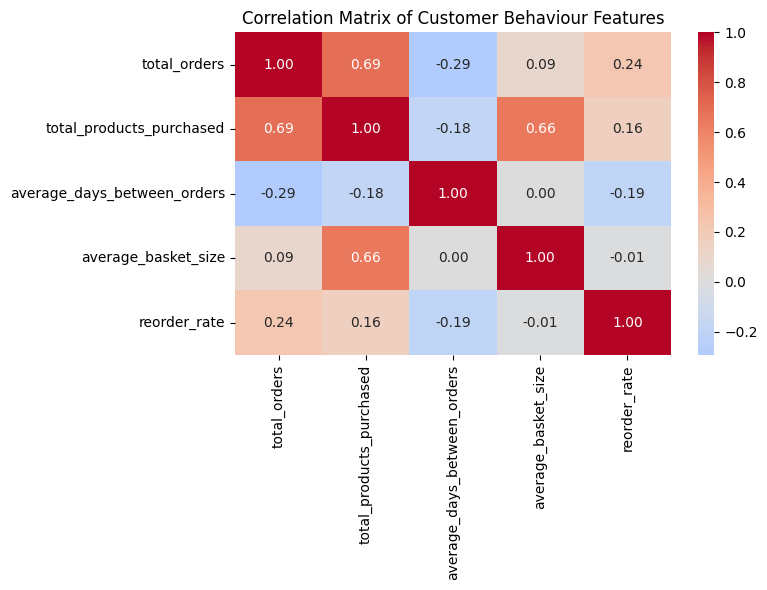

In [ ]:
cluster_cols = [
    "total_orders",
    "total_products_purchased",
    "average_days_between_orders",
    "average_basket_size",
    "reorder_rate"
]

corr = customer_df[cluster_cols].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Matrix of Customer Behaviour Features")

plt.tight_layout()
plt.show()

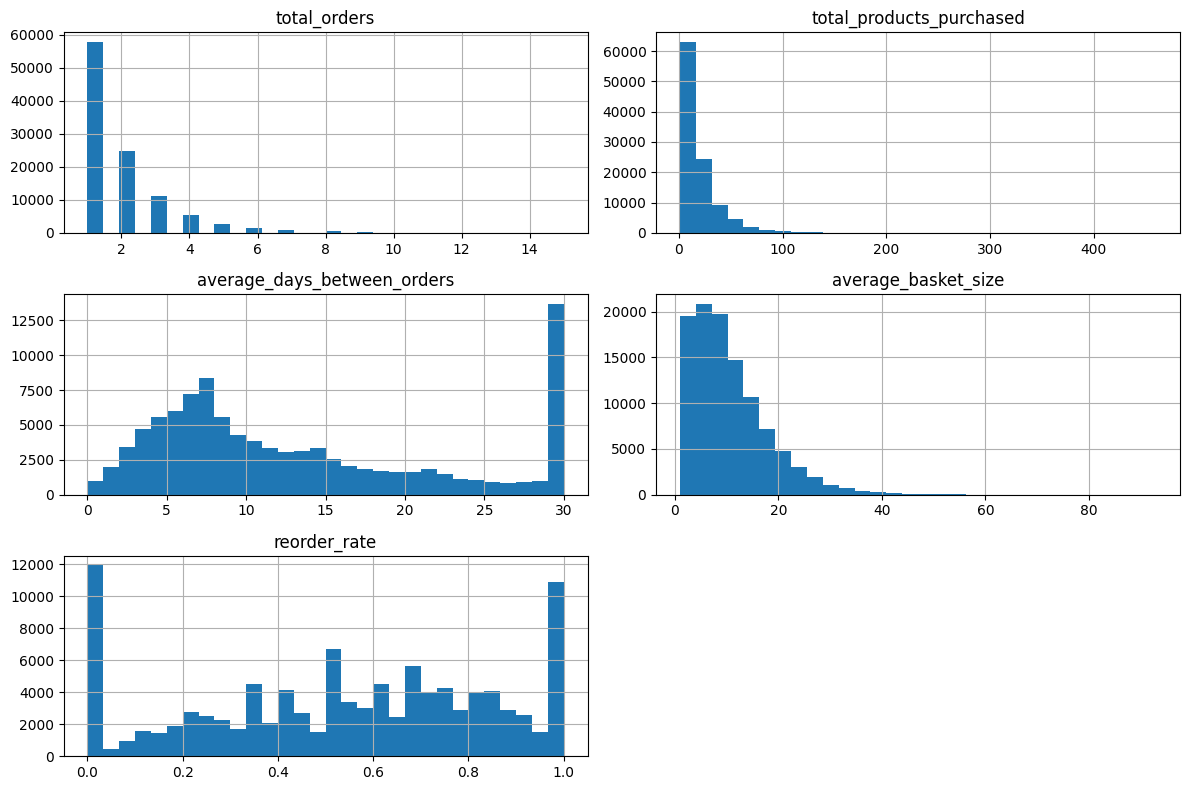

In [ ]:
customer_df[cluster_cols].hist(
    figsize=(12, 8),
    bins=30
)

plt.tight_layout()
plt.show()

In [ ]:
customer_df[cluster_cols].skew().sort_values(ascending=False)

,0
total_products_purchased,3.00
total_orders,2.29
average_basket_size,1.38
average_days_between_orders,0.70
reorder_rate,-0.25


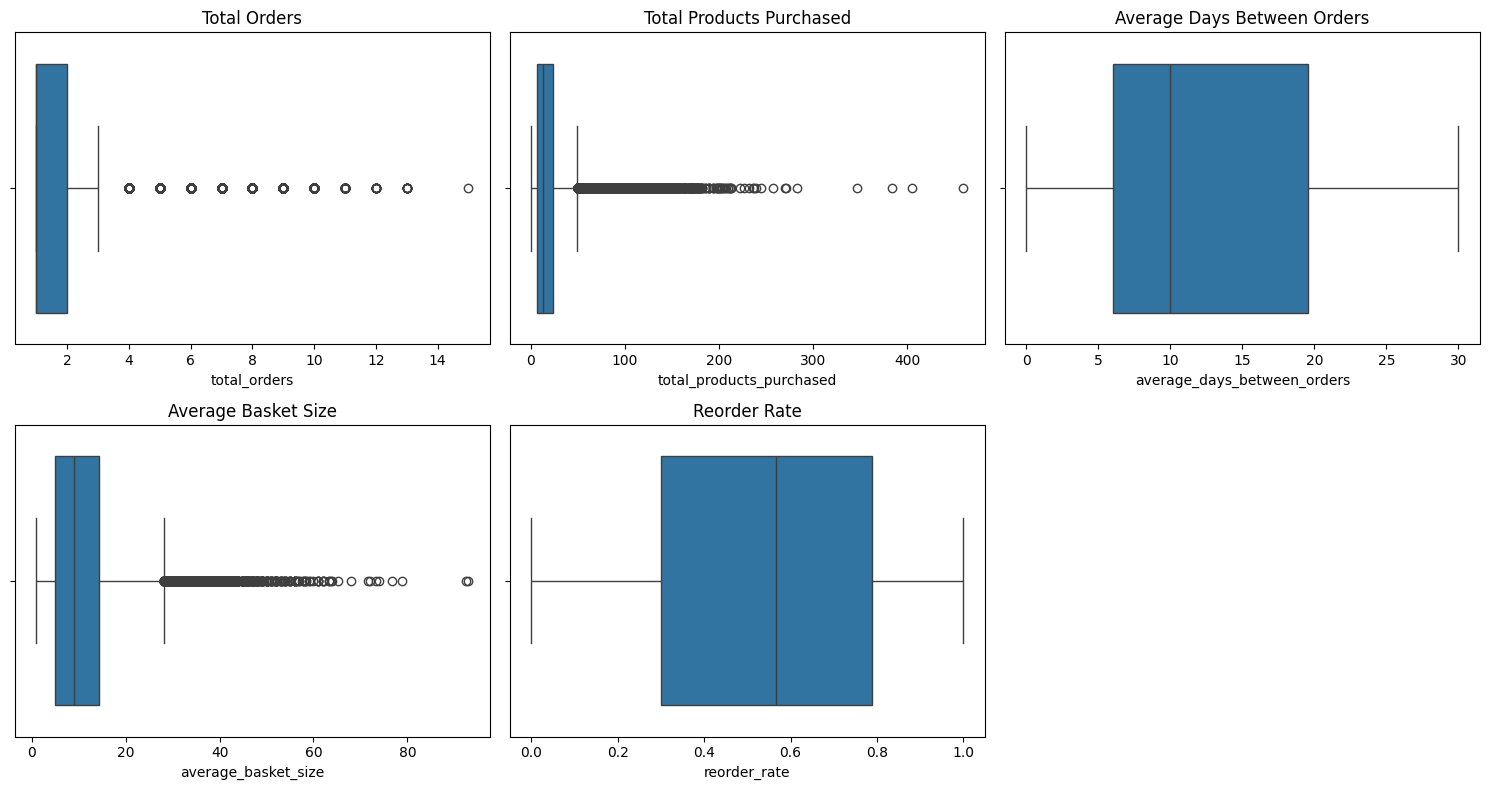

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

sns.boxplot(x=customer_df["total_orders"], ax=axes[0, 0])
axes[0, 0].set_title("Total Orders")

sns.boxplot(x=customer_df["total_products_purchased"], ax=axes[0, 1])
axes[0, 1].set_title("Total Products Purchased")

sns.boxplot(x=customer_df["average_days_between_orders"], ax=axes[0, 2])
axes[0, 2].set_title("Average Days Between Orders")

sns.boxplot(x=customer_df["average_basket_size"], ax=axes[1, 0])
axes[1, 0].set_title("Average Basket Size")

sns.boxplot(x=customer_df["reorder_rate"], ax=axes[1, 1])
axes[1, 1].set_title("Reorder Rate")

axes[1, 2].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
customer_df.describe()

,user_id,total_orders,total_products_purchased,average_days_between_orders,average_basket_size,reorder_rate
count,105273.00,105273.00,105273.00,98918.00,105273.00,105273.00
mean,103247.71,1.90,19.18,13.16,10.69,0.54
std,59572.49,1.39,19.98,9.15,7.38,0.31
min,2.00,1.00,1.00,0.00,1.00,0.00
25%,51653.00,1.00,7.00,6.00,5.00,0.30
50%,103235.00,1.00,13.00,10.00,9.00,0.57
75%,154780.00,2.00,24.00,19.53,14.24,0.79
max,206209.00,15.00,460.00,30.00,93.00,1.00


In [ ]:
# Check missing values in customer_df
customer_df.isnull().sum()

,0
user_id,0
total_orders,0
total_products_purchased,0
average_days_between_orders,6355
average_basket_size,0
reorder_rate,0


In [ ]:
customer_df.loc[
    customer_df["average_days_between_orders"].isna(),
    "total_orders"
].value_counts().sort_index()

,count
total_orders,
1,6355


Here we see that first time customers have all the missing values for the average days between orders because this was engineered from days since prior order. In order to deal with this, we will separate out the first time customers as a new cluster manually before doing K means clusters in the modelling section.

In [ ]:


customer_df["log_total_orders"] = np.log(
    customer_df["total_orders"]
)
#we take log1p when the minimum is 0

customer_df["log_total_products_purchased"] = np.log(
    customer_df["total_products_purchased"]
)

customer_df["log_average_basket_size"] = np.log(
    customer_df["average_basket_size"]
)

In [ ]:
cluster_cols = [
    "log_total_orders",
    "log_total_products_purchased",
    "average_days_between_orders",
    "log_average_basket_size",
    "reorder_rate"
]

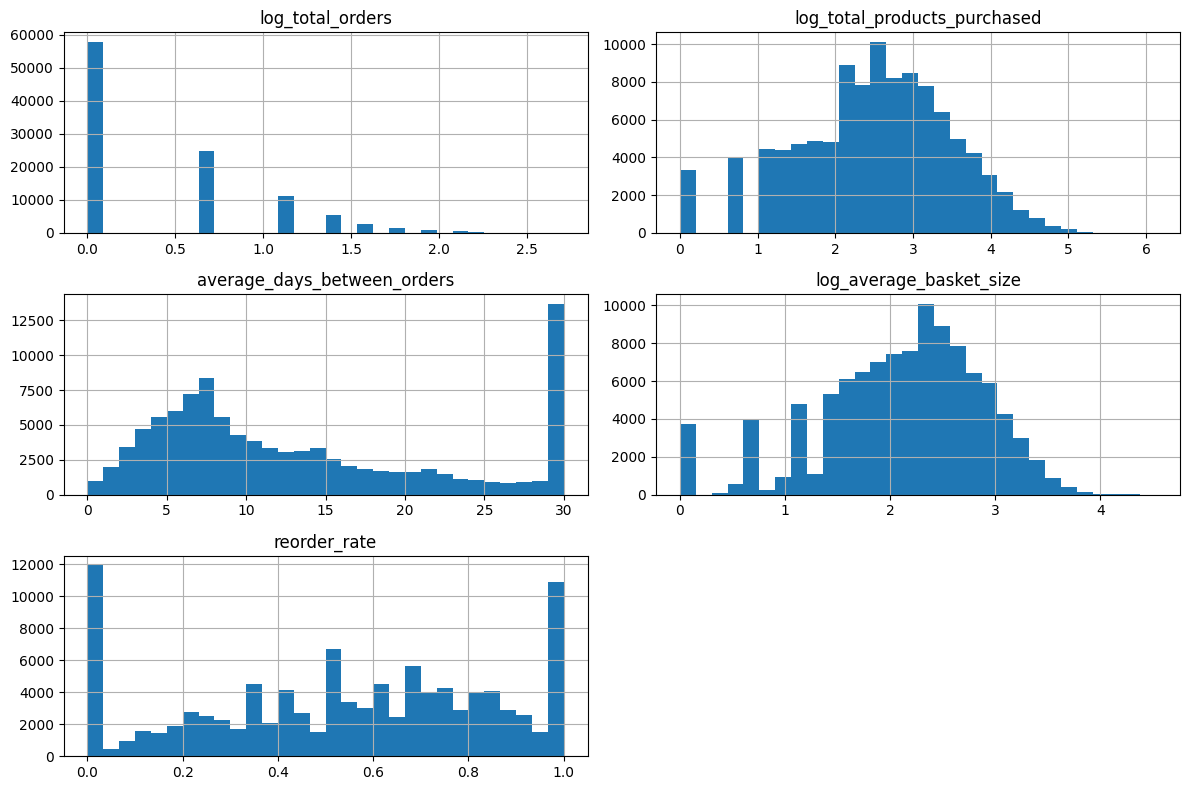

In [ ]:
customer_df[cluster_cols].hist(
    figsize=(12, 8),
    bins=30
)

plt.tight_layout()
plt.show()

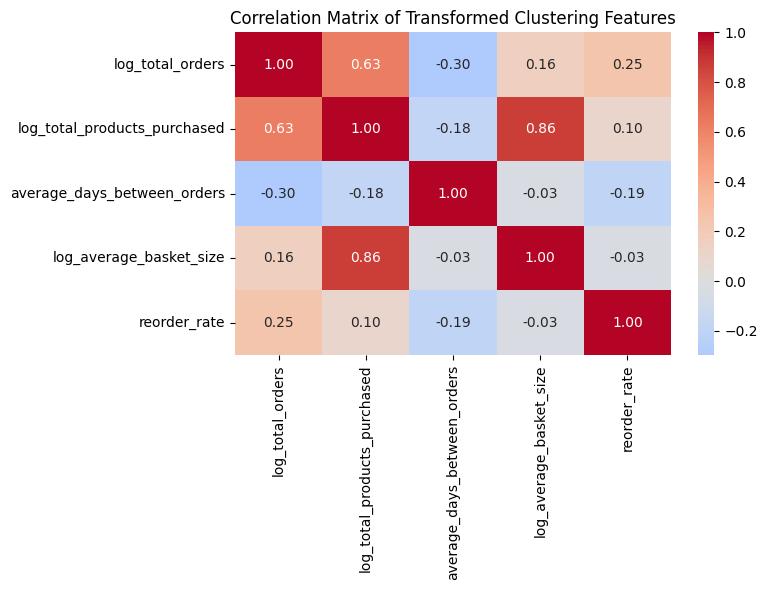

In [ ]:
corr = customer_df[cluster_cols].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Matrix of Transformed Clustering Features")

plt.tight_layout()
plt.show()

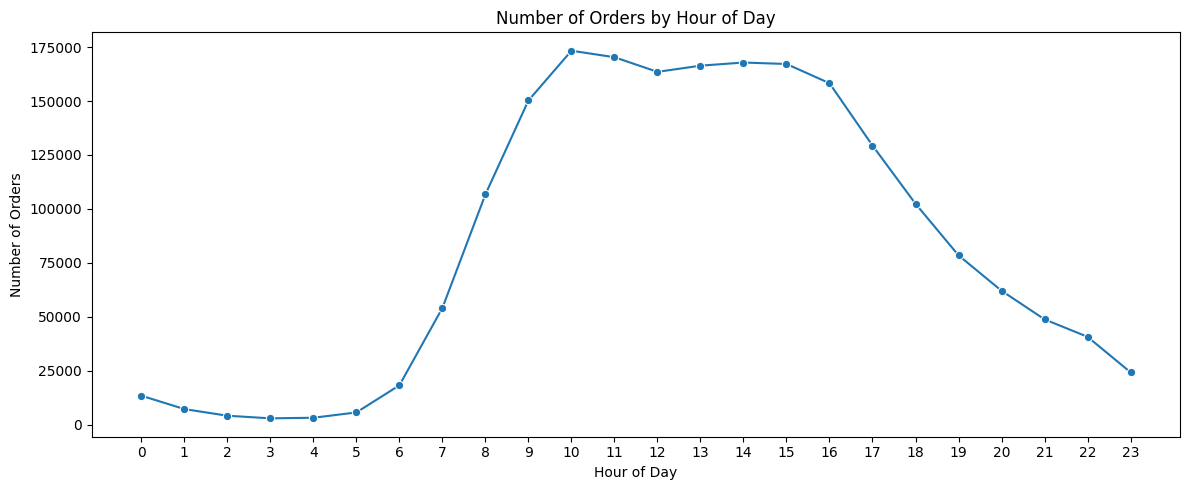

In [ ]:
hour_counts = df["order_hour_of_day"].value_counts().sort_index()

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=hour_counts.index,
    y=hour_counts.values,
    marker="o"
)

plt.title("Number of Orders by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Orders")

plt.xticks(range(0, 24))

plt.tight_layout()
plt.show()

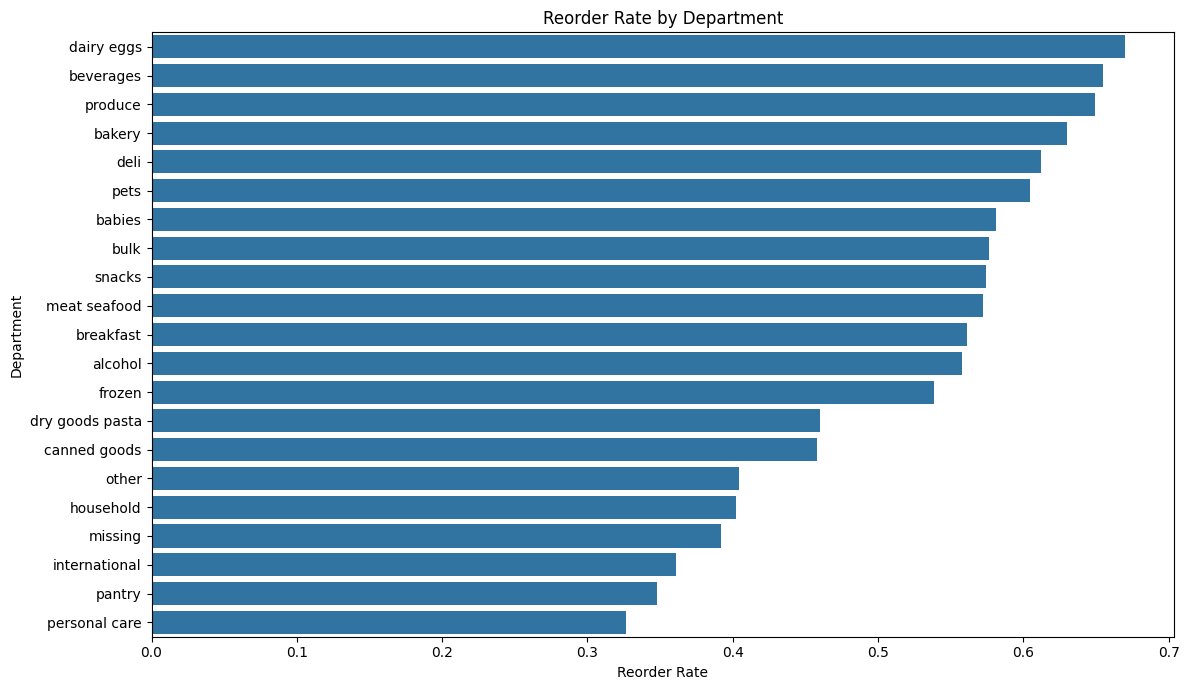

In [ ]:
department_reorder = (
    df.groupby("department")["reordered"]
      .mean()
      .sort_values(ascending=False)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=department_reorder.values,
    y=department_reorder.index
)

plt.title("Reorder Rate by Department")
plt.xlabel("Reorder Rate")
plt.ylabel("Department")

plt.tight_layout()
plt.show()

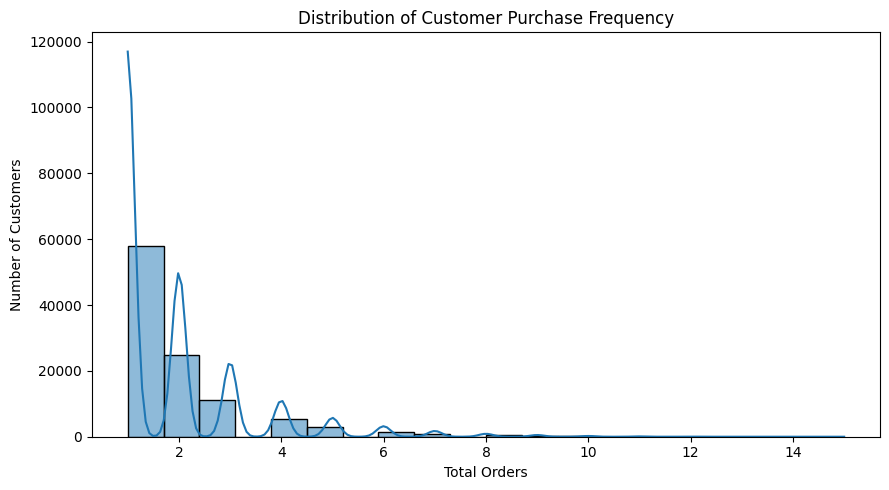

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=customer_df,
    x="total_orders",
    bins=20,
    kde=True
)

plt.title("Distribution of Customer Purchase Frequency")
plt.xlabel("Total Orders")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [ ]:
cluster_cols = [
    "log_total_orders",
    "average_days_between_orders",
    "log_average_basket_size",
    "reorder_rate"
]

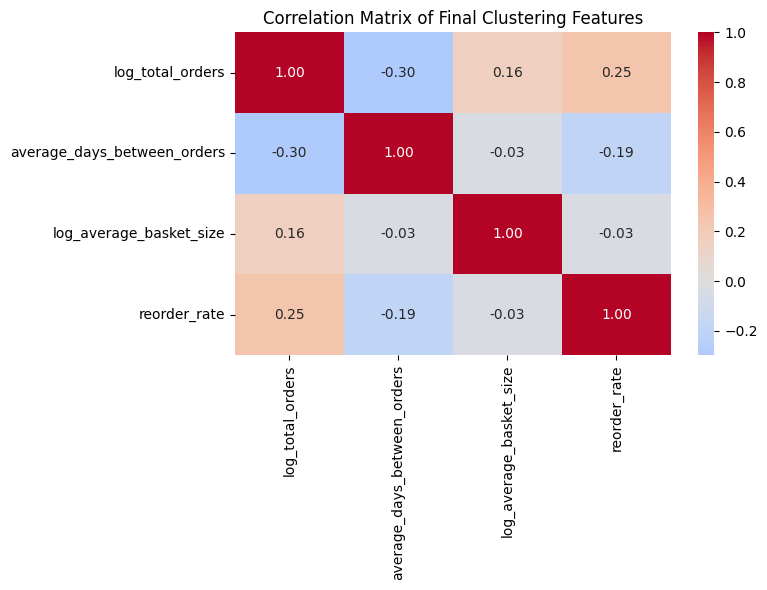

In [ ]:
final_corr = customer_df[cluster_cols].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    final_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Matrix of Final Clustering Features")

plt.tight_layout()
plt.show()

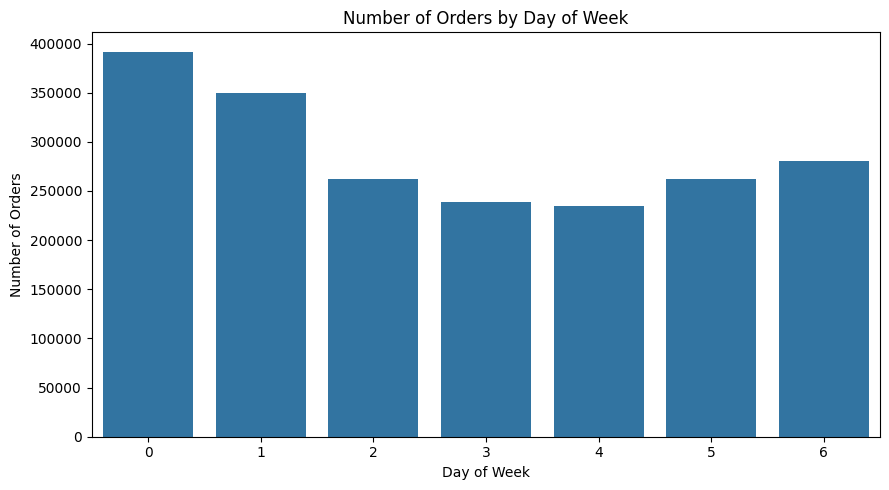

In [ ]:
dow_counts = df["order_dow"].value_counts().sort_index()

plt.figure(figsize=(9, 5))

sns.barplot(
    x=dow_counts.index,
    y=dow_counts.values
)

plt.title("Number of Orders by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Orders")

plt.tight_layout()
plt.show()

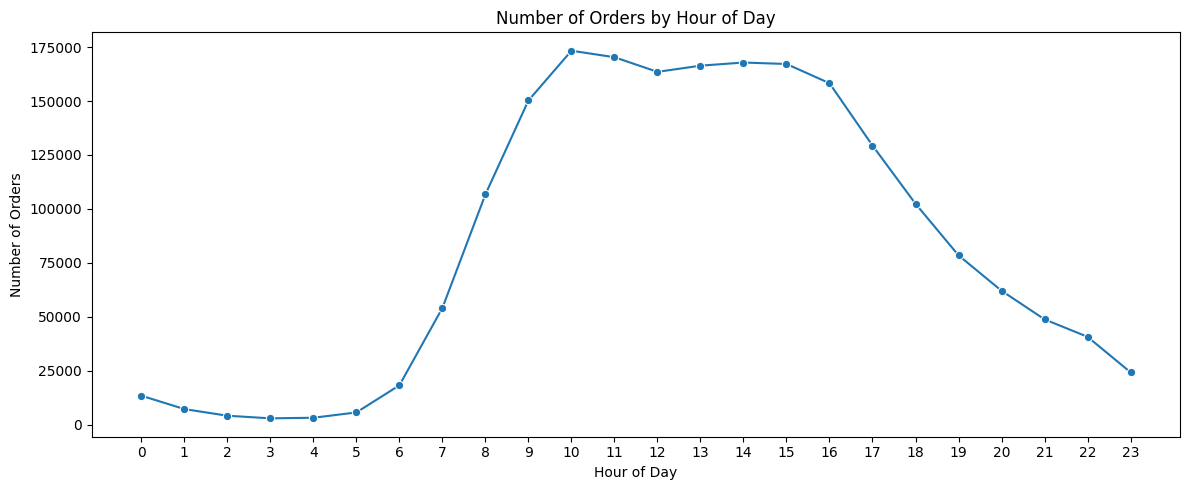

In [ ]:
hour_counts = df["order_hour_of_day"].value_counts().sort_index()

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=hour_counts.index,
    y=hour_counts.values,
    marker="o"
)

plt.title("Number of Orders by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Orders")

plt.xticks(range(0, 24))

plt.tight_layout()
plt.show()

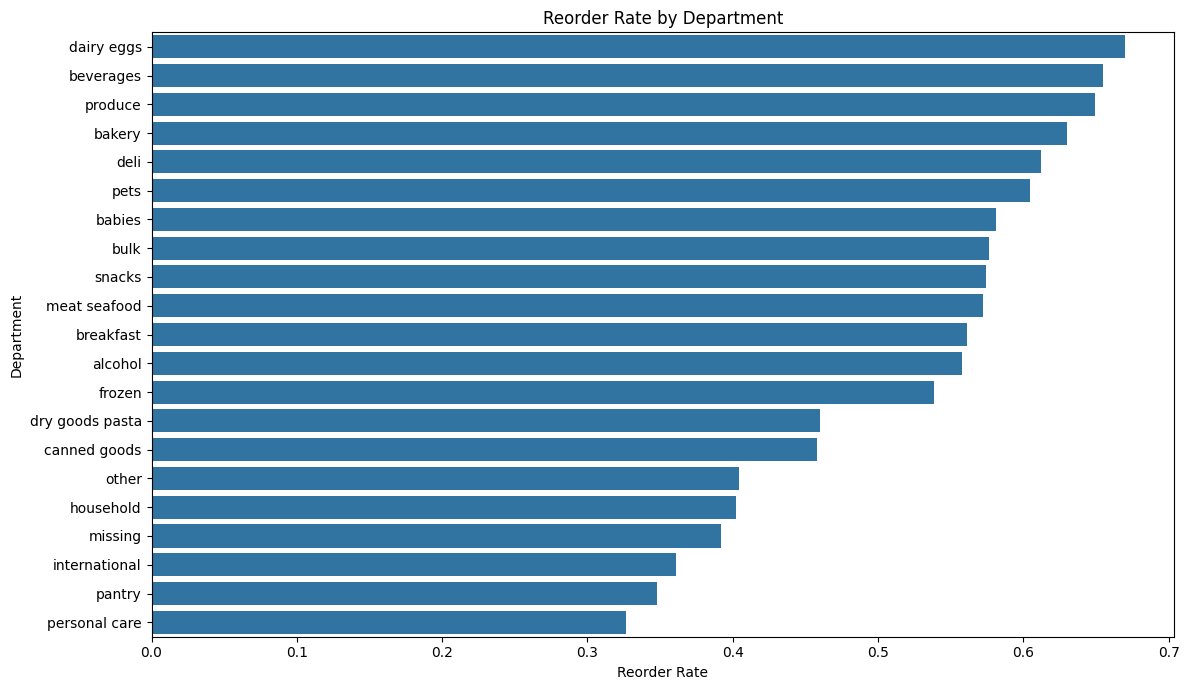

In [ ]:
department_reorder = (
    df.groupby("department")["reordered"]
      .mean()
      .sort_values(ascending=False)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=department_reorder.values,
    y=department_reorder.index
)

plt.title("Reorder Rate by Department")
plt.xlabel("Reorder Rate")
plt.ylabel("Department")

plt.tight_layout()
plt.show()

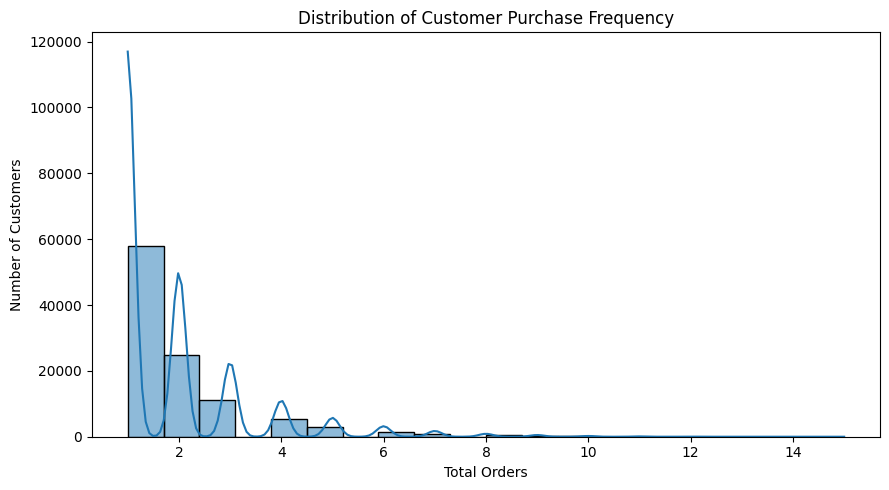

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=customer_df,
    x="total_orders",
    bins=20,
    kde=True
)

plt.title("Distribution of Customer Purchase Frequency")
plt.xlabel("Total Orders")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

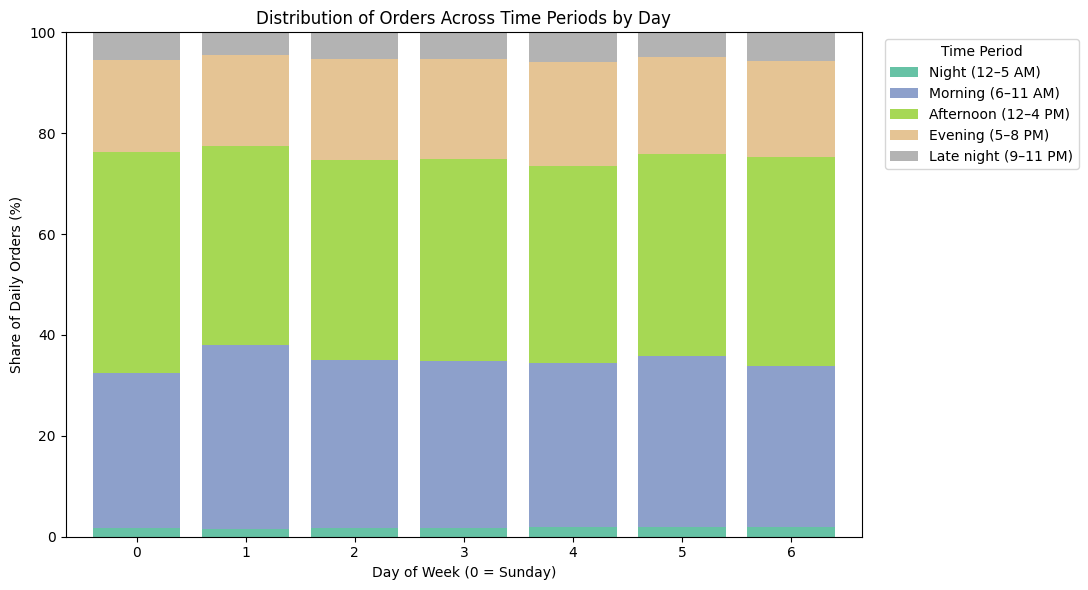

In [ ]:
df["time_period"] = pd.cut(
    df["order_hour_of_day"],
    bins=[-1, 5, 11, 16, 20, 23],
    labels=["Night (12–5 AM)",
            "Morning (6–11 AM)",
            "Afternoon (12–4 PM)",
            "Evening (5–8 PM)",
            "Late night (9–11 PM)"]
)

# Count unique orders by day and time period
orders = df.groupby(
    ["order_dow", "time_period"], observed=False
)["order_id"].nunique().unstack(fill_value=0)

# Convert counts to percentages within each day
order_share = orders.div(orders.sum(axis=1), axis=0) * 100

# Plot a single 100% stacked bar chart
ax = order_share.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6),
    colormap="Set2",
    width=0.8
)

ax.set_title("Distribution of Orders Across Time Periods by Day")
ax.set_xlabel("Day of Week (0 = Sunday)")
ax.set_ylabel("Share of Daily Orders (%)")
ax.legend(title="Time Period", bbox_to_anchor=(1.02, 1),
          loc="upper left")
ax.set_ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

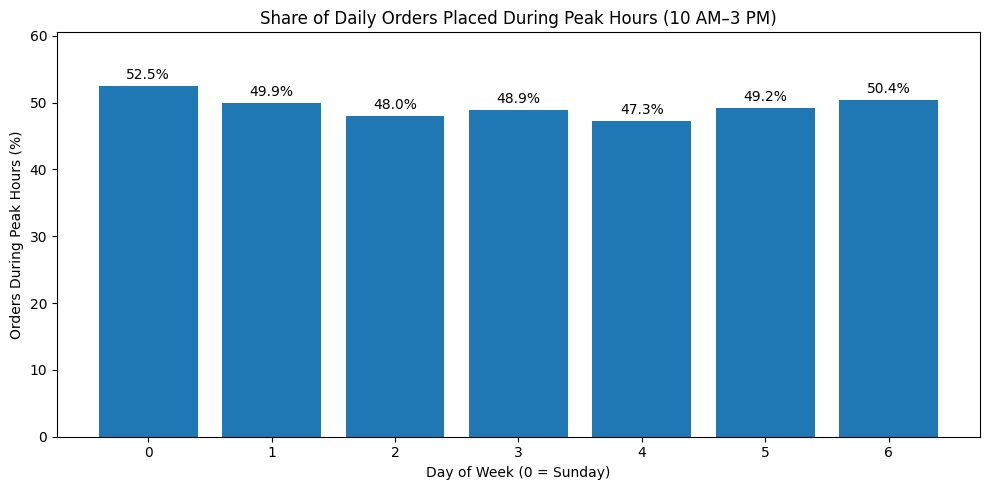

In [ ]:
# Define peak hours: 10 AM to 3 PM inclusive
peak_hours = df["order_hour_of_day"].between(10, 15)

# Count unique orders per day
total_orders = df.groupby("order_dow")["order_id"].nunique()

# Count unique orders during peak hours per day
peak_orders = (
    df[peak_hours]
    .groupby("order_dow")["order_id"]
    .nunique()
)

# Calculate peak-hour orders as a percentage of daily orders
peak_share = (peak_orders / total_orders * 100).reindex(range(7))

# Plot
plt.figure(figsize=(10, 5))
bars = plt.bar(peak_share.index, peak_share.values)

plt.bar_label(bars, fmt="%.1f%%", padding=3)
plt.title("Share of Daily Orders Placed During Peak Hours (10 AM–3 PM)")
plt.xlabel("Day of Week (0 = Sunday)")
plt.ylabel("Orders During Peak Hours (%)")
plt.xticks(range(7))
plt.ylim(0, peak_share.max() + 8)
plt.tight_layout()
plt.show()

### Preparing the data for Clustering

In [ ]:
df.head()

,user_id,order_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_id,add_to_cart_order,reordered,department_id,department,product_name,total_items_per_order,average_days_between_orders,total_products_purchased,total_orders,reorder_rate,average_basket_size,time_period
0,87616,4852,39,1,12,4.00,67,1,0,20,deli,fresh dips tapenades,15,5.00,56,3,0.88,18.67,Afternoon (12–4 PM)
1,87616,4852,39,1,12,4.00,89,2,1,13,pantry,salad dressing toppings,15,5.00,56,3,0.88,18.67,Afternoon (12–4 PM)
2,87616,4852,39,1,12,4.00,108,3,1,16,dairy eggs,other creams cheeses,15,5.00,56,3,0.88,18.67,Afternoon (12–4 PM)
3,87616,4852,39,1,12,4.00,24,4,1,4,produce,fresh fruits,15,5.00,56,3,0.88,18.67,Afternoon (12–4 PM)
4,87616,4852,39,1,12,4.00,116,5,1,1,frozen,frozen produce,15,5.00,56,3,0.88,18.67,Afternoon (12–4 PM)


In [ ]:
new_customers = customer_df[customer_df["average_days_between_orders"].isna()].copy()
model_df = customer_df.dropna(subset=["average_days_between_orders"]).copy()

print(len(new_customers), len(model_df))   # 6355, 98918

6355 98918


In [ ]:


scaler = StandardScaler()
X = scaler.fit_transform(model_df[cluster_cols])

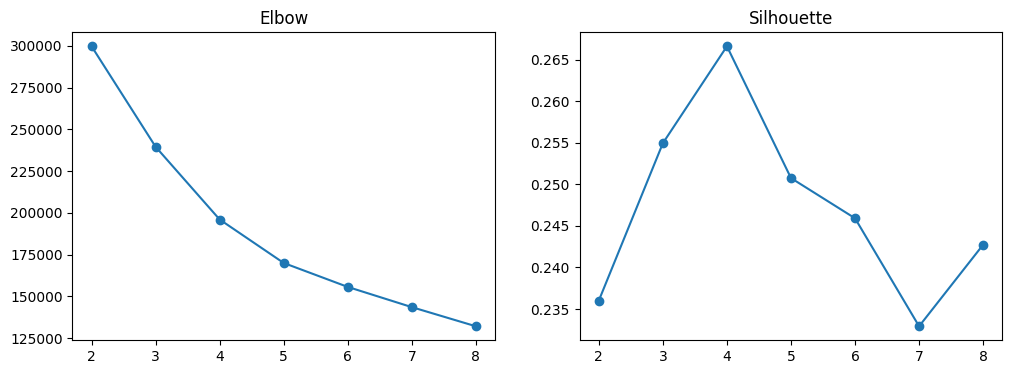

In [ ]:



inertia, sil = [], []
ks = range(2, 9)
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_, sample_size=10000, random_state=42))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertia, marker="o"); ax[0].set_title("Elbow")
ax[1].plot(ks, sil, marker="o");     ax[1].set_title("Silhouette")
plt.show()

The elbow method showed a clear reduction in inertia up to k=4, after which improvements diminished. The silhouette score was highest at k=4 (≈0.27), so four clusters were selected. The moderate silhouette value indicates some overlap between segments, which is expected for behavioural customer data

In [ ]:
best_k = 4
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
model_df["cluster"] = kmeans.fit_predict(X).astype(str)

In [ ]:
new_customers["cluster"] = "4"
final_model_df = pd.concat([model_df, new_customers], ignore_index=True)

In [ ]:
final_model_df.head()

,user_id,total_orders,total_products_purchased,average_days_between_orders,average_basket_size,reorder_rate,log_total_orders,log_total_products_purchased,log_average_basket_size,cluster
0,2,2,11,6.82,5.55,0.36,0.69,2.40,1.71,1
1,3,3,19,12.42,6.89,0.47,1.10,2.94,1.93,2
2,7,1,24,30.00,24.00,0.83,0.00,3.18,3.18,0
3,10,1,30,14.00,30.00,0.43,0.00,3.40,3.40,1
4,11,1,11,30.00,11.00,0.27,0.00,2.40,2.40,0


## Clusters EDA

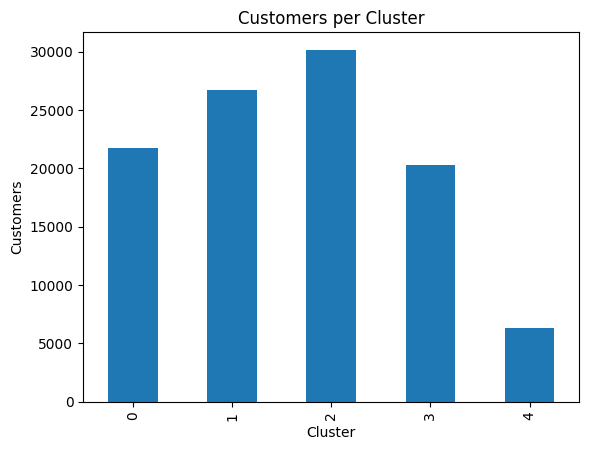

In [ ]:
final_model_df["cluster"].value_counts().sort_index().plot(kind="bar")
plt.title("Customers per Cluster")
plt.xlabel("Cluster"); plt.ylabel("Customers")
plt.show()

In [ ]:
profile = final_model_df.groupby("cluster").agg(
    customers=("user_id", "nunique"),
    avg_orders=("total_orders", "mean"),
    median_orders=("total_orders", "median"),
    avg_basket=("average_basket_size", "mean"),
    median_basket=("average_basket_size", "median"),
    avg_days_between=("average_days_between_orders", "mean"),
    avg_reorder_rate=("reorder_rate", "mean")
).round(2)

profile["customer_share_%"] = (
    profile["customers"] / profile["customers"].sum() * 100
).round(2)

print(profile)

         customers  avg_orders  median_orders  avg_basket  median_basket  \
cluster                                                                    
0            21772        1.31           1.00       11.36          10.00   
1            26725        1.27           1.00       11.63          10.00   
2            30144        3.51           3.00       13.06          11.55   
3            20277        1.26           1.00        5.43           4.14   
4             6355        1.00           1.00        9.99           8.00   

         avg_days_between  avg_reorder_rate  customer_share_%  
cluster                                                        
0                   26.91              0.39             20.68  
1                    8.23              0.36             25.39  
2                    8.48              0.69             28.63  
3                   11.84              0.87             19.26  
4                     NaN              0.00              6.04  


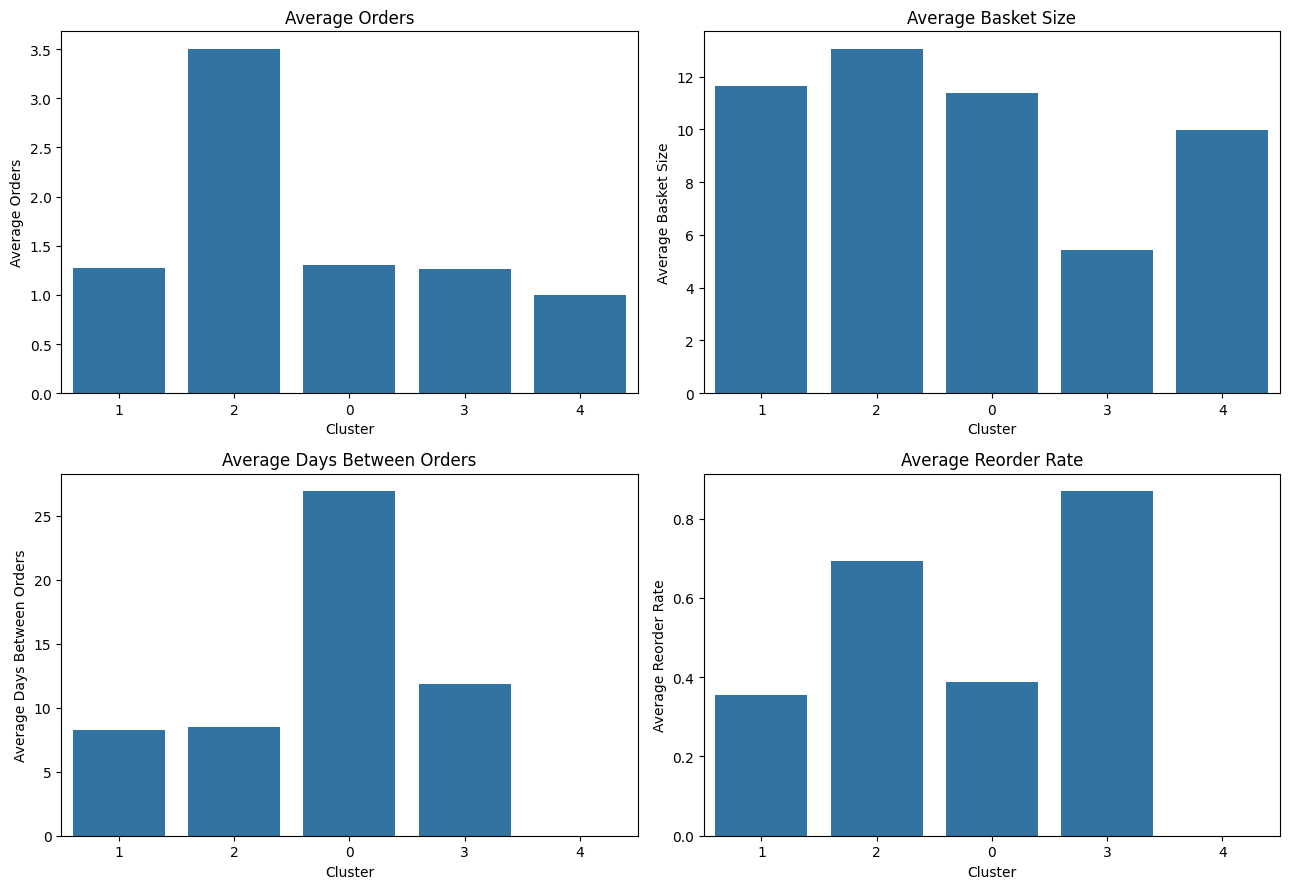

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

metrics = [
    ("total_orders", "Average Orders"),
    ("average_basket_size", "Average Basket Size"),
    ("average_days_between_orders", "Average Days Between Orders"),
    ("reorder_rate", "Average Reorder Rate")
]

for ax, (col, title) in zip(axes.flat, metrics):
    sns.barplot(
        data=final_model_df,
        x="cluster",
        y=col,
        errorbar=None,
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Cluster")
    ax.set_ylabel(title)

plt.tight_layout()
plt.show()

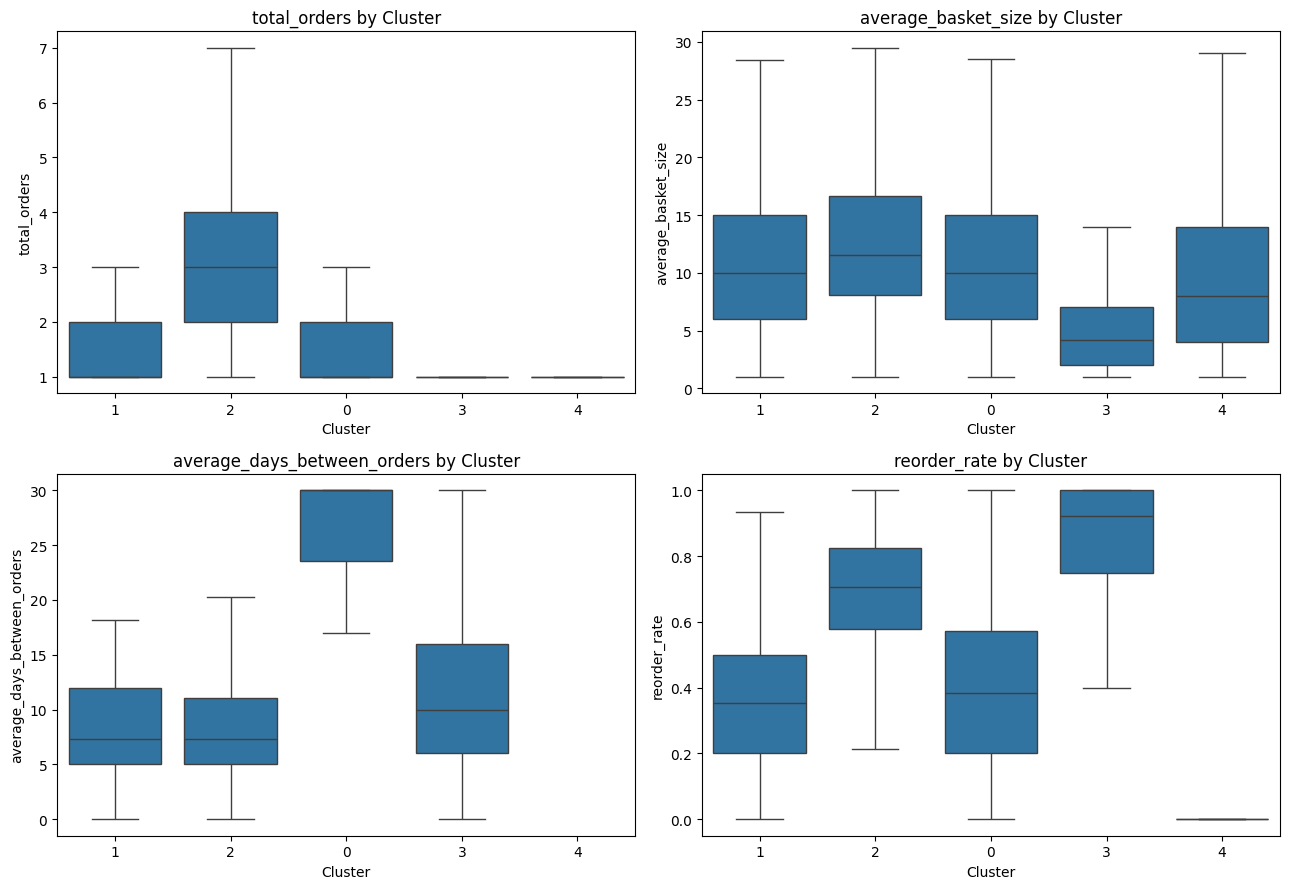

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

metrics = [
    "total_orders",
    "average_basket_size",
    "average_days_between_orders",
    "reorder_rate"
]

for ax, col in zip(axes.flat, metrics):
    sns.boxplot(
        data=final_model_df,
        x="cluster",
        y=col,
        ax=ax,
        showfliers=False
    )
    ax.set_title(f"{col} by Cluster")
    ax.set_xlabel("Cluster")

plt.tight_layout()
plt.show()

Cluster 0 - Infrequent Shoppers : these customers have an average of 1.31 orders and an average basket size of 11.36 products. Their average interval between orders is 26.91 days and their reorder rate is 39%.
Cluster 1 - Frequent Shoppers : This is the second-largest cluster, with an average of 1.27 orders, a basket size of 11.63 products, an average interval of 8.23 days, and a reorder rate of 36%.
Cluster 2 - Highly Frequent Shoppers: This is the largest cluster, with the highest average number of orders (3.51), the largest average basket size (13.06 products), and a high reorder rate of 69%. Its average interval between orders is 8.48 days.
Cluster 3 - Small Basket Shoppers: These customers have the highest average reorder rate at 87%, but the smallest average basket at 5.43 products. Their average number of orders is 1.26, and their average interval is 11.84 days.
Cluster 4 - First Time Shoppers: The average basket contains 9.99 products, and the reorder rate is zero because no previously reordered products are recorded for this segment.

Checking if the clusters differ by departments too

In [ ]:
# Keep only the columns needed from the customer-level cluster data
customer_clusters = final_model_df[["user_id", "cluster"]].drop_duplicates()

# Add cluster labels to the original transaction data
cluster_transactions = df.merge(
    customer_clusters,
    on="user_id",
    how="inner"
)

print(cluster_transactions[["user_id", "department", "cluster"]].head())

   user_id  department cluster
0    87616        deli       2
1    87616      pantry       2
2    87616  dairy eggs       2
3    87616     produce       2
4    87616      frozen       2


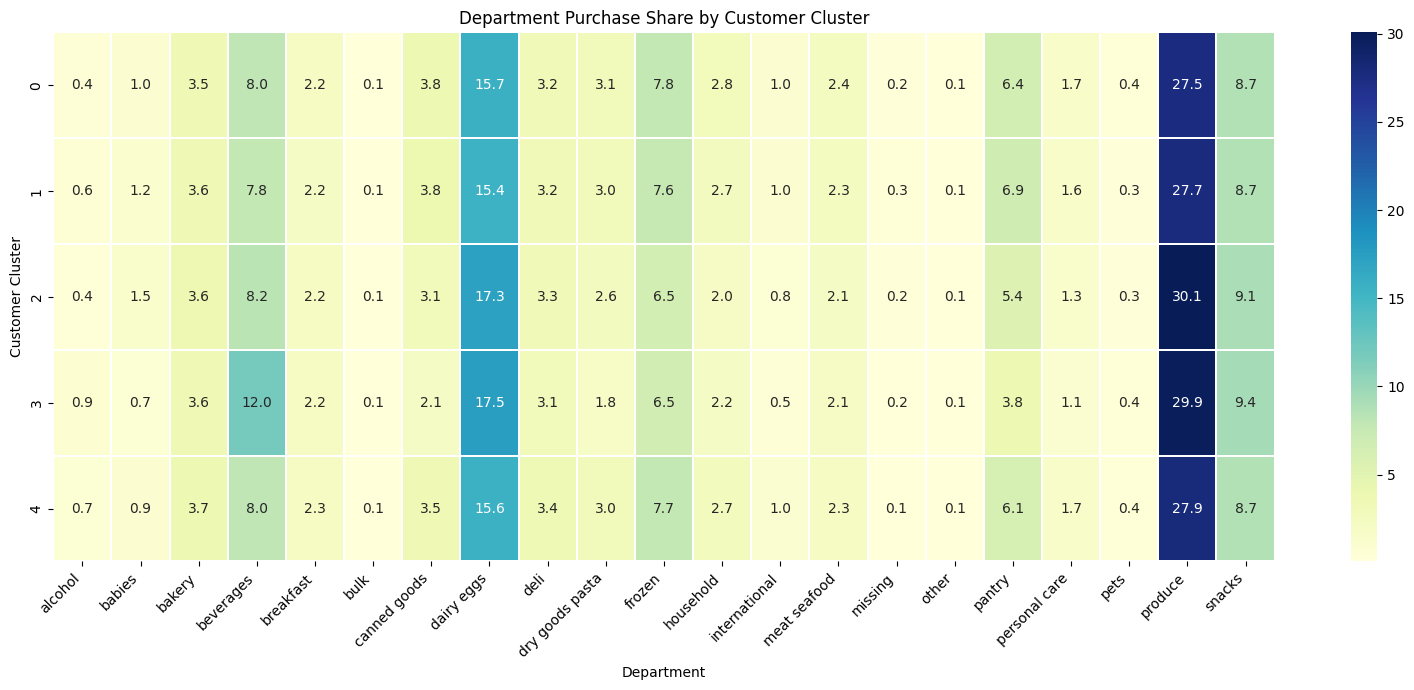

In [ ]:


# Count product records by cluster and department
department_counts = pd.crosstab(
    cluster_transactions["cluster"],
    cluster_transactions["department"]
)

# Convert counts into percentages within each cluster
department_share = department_counts.div(
    department_counts.sum(axis=1),
    axis=0
) * 100

# Plot the heatmap
plt.figure(figsize=(16, 7))

sns.heatmap(
    department_share,
    cmap="YlGnBu",
    annot=True,
    fmt=".1f",
    linewidths=0.3
)

plt.title("Department Purchase Share by Customer Cluster")
plt.xlabel("Department")
plt.ylabel("Customer Cluster")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
top_departments = (
    department_share
    .reset_index()
    .melt(
        id_vars="cluster",
        var_name="department",
        value_name="purchase_share_pct"
    )
    .sort_values(
        ["cluster", "purchase_share_pct"],
        ascending=[True, False]
    )
    .groupby("cluster")
    .head(5)
)

print(top_departments.round(2).to_string(index=False))

cluster department  purchase_share_pct
      0    produce               27.52
      0 dairy eggs               15.74
      0     snacks                8.65
      0  beverages                8.03
      0     frozen                7.79
      1    produce               27.66
      1 dairy eggs               15.44
      1     snacks                8.69
      1  beverages                7.81
      1     frozen                7.58
      2    produce               30.07
      2 dairy eggs               17.30
      2     snacks                9.08
      2  beverages                8.19
      2     frozen                6.46
      3    produce               29.94
      3 dairy eggs               17.53
      3  beverages               11.96
      3     snacks                9.36
      3     frozen                6.53
      4    produce               27.90
      4 dairy eggs               15.61
      4     snacks                8.67
      4  beverages                7.97
      4     frozen       

The clusters do not differ by departments much as departments are like produce, dairy & eggs, snacks, beverages and frozen are common for all the clusters and the percentages are not varying alot.

### Comparing time for transformations

In [ ]:


start = time.perf_counter()

spark_transformed = (
    adf.select("user_id", "order_id", "product_id", "reordered")
       .filter(f.col("reordered") == 1)
       .withColumn("reorder_flag", f.lit(1))
)

spark_transform_time = time.perf_counter() - start

print(f"Spark transformation-definition time: "
      f"{spark_transform_time:.6f} seconds")

Spark transformation-definition time: 0.040530 seconds


In [ ]:


start = time.perf_counter()

pandas_transformed = (
    df.loc[df["reordered"] == 1,
           ["user_id", "order_id", "product_id", "reordered"]]
      .assign(reorder_flag=1)
)

pandas_transform_time = time.perf_counter() - start

print(f"Pandas transformation time: "
      f"{pandas_transform_time:.6f} seconds")

Pandas transformation time: 0.061248 seconds


In [ ]:
print(f"Spark:  {spark_transform_time:.6f} seconds")
print(f"Pandas: {pandas_transform_time:.6f} seconds")

if spark_transform_time < pandas_transform_time:
    print("Spark was faster at defining the transformations.")
elif pandas_transform_time < spark_transform_time:
    print("Pandas was faster at completing its operations.")
else:
    print("Both took the same amount of time.")

Spark:  0.040530 seconds
Pandas: 0.061248 seconds
Spark was faster at defining the transformations.


<Axes: ylabel='total_orders'>

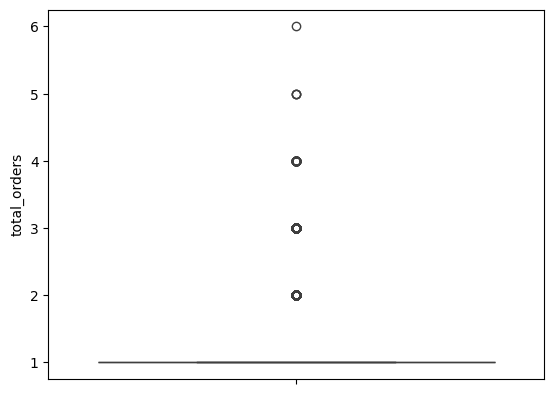

In [ ]:
cluster_3 = final_model_df[final_model_df['cluster'] == '3']
sns.boxplot(data=cluster_3, y='total_orders')

In [ ]:
cluster_3.describe()

,user_id,total_orders,total_products_purchased,average_days_between_orders,average_basket_size,reorder_rate,log_total_orders,log_total_products_purchased,log_average_basket_size
count,20277.00,20277.00,20277.00,20277.00,20277.00,20277.00,20277.00,20277.00,20277.00
mean,102912.24,1.26,6.21,11.84,5.43,0.87,0.17,1.56,1.41
std,59683.21,0.52,4.36,7.92,4.21,0.16,0.32,0.78,0.78
min,17.00,1.00,1.00,0.00,1.00,0.33,0.00,0.00,0.00
25%,51204.00,1.00,3.00,6.00,2.00,0.75,0.00,1.10,0.69
50%,103120.00,1.00,5.00,10.00,4.14,0.92,0.00,1.61,1.42
75%,154533.00,1.00,9.00,16.00,7.00,1.00,0.00,2.20,1.95
max,206205.00,6.00,32.00,30.00,32.00,1.00,1.79,3.47,3.47
